# Lecture 7: Attention, live demos
Each cell is a short demo (under 30 s). Numbers match the slides.

Needs: `pip install numpy matplotlib tiktoken torch transformers`

## Setup
Helper functions used by the demos below. This cell prints nothing.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=3, suppress=True)

def softmax(x, axis=-1):
    e = np.exp(x - x.max(axis=axis, keepdims=True))   # subtract max for stability
    return e / e.sum(axis=axis, keepdims=True)

def bars(words, w, title, ax=None):
    ax = ax or plt.gca()
    ax.bar(words, w, color="#6A3D9A"); ax.set_ylim(0, 1); ax.set_title(title)

## 1. Tokenization (toy): text → tokens → IDs → embeddings

Each word becomes an ID, and each ID picks one row of the embedding table. Expect 4 tokens, 4 IDs and 4 vectors: the model only ever sees the numbers.

In [ ]:
vocab = ["a", "blue", "cat", "creature", "dog", "fluffy", "forest", "the"]
tok2id = {t: i for i, t in enumerate(vocab)}

text = "a fluffy blue creature"
tokens = text.split()                       # 1. tokenize
ids = [tok2id[t] for t in tokens]           # 2. look up IDs
W_E = np.random.default_rng(0).normal(size=(len(vocab), 4))   # embedding table (learned in practice)
E = W_E[ids]                                # 3. embed = pick rows

print("tokens:", tokens)
print("ids:   ", ids)
print("embeddings (one row per token):\n", E)

tokens: ['a', 'fluffy', 'blue', 'creature']
ids:    [0, 5, 1, 3]
embeddings (one row per token):
 [[ 0.126 -0.132  0.64   0.105]
 [-0.129  1.366 -0.665  0.352]
 [-0.536  0.362  1.304  0.947]
 [-2.325 -0.219 -1.246 -0.732]]


## 2. A real tokenizer (GPT-2): words get split into pieces

Real tokenizers split text into subword pieces. Common words take 1 token, numbers get split oddly, and the Hindi phrase takes many more tokens than the English one.

In [ ]:
try:
    import tiktoken
    enc = tiktoken.get_encoding("gpt2")
    for s in ["a fluffy blue creature", " unbelievably", " strawberry", "12345 + 678", "नमस्ते दुनिया"]:
        ids = enc.encode(s)
        print(f"{s!r:28} -> {len(ids):2} tokens: {[enc.decode([i]) for i in ids]}")
except Exception as e:
    print("Run `pip install tiktoken` (needs internet the first time):", e)

'a fluffy blue creature'     ->  4 tokens: ['a', ' fluffy', ' blue', ' creature']
' unbelievably'              ->  1 tokens: [' unbelievably']
' strawberry'                ->  1 tokens: [' strawberry']
'12345 + 678'                ->  5 tokens: ['123', '45', ' +', ' 6', '78']
'नमस्ते दुनिया'              -> 23 tokens: ['�', '�', '�', '�', '�', '�', '�', '�', '�', '�', '�', '�', ' �', '�', '�', '�', '�', '�', '�', '�', '�', '�', 'ा']


## 3. Attention for one word: "creature" (slides: scores → softmax → values)

The query for "creature" is scored against every key, softmax turns the scores into weights, and the weights blend the values. Most of the weight should go to *fluffy* and *blue*, so the update ΔE carries "fluffy + blue" meaning.

scores:  [-1.5  3.   2.7  0. ]
weights: [0.006 0.555 0.411 0.028]
update ΔE: [0.555 0.411 0.028]


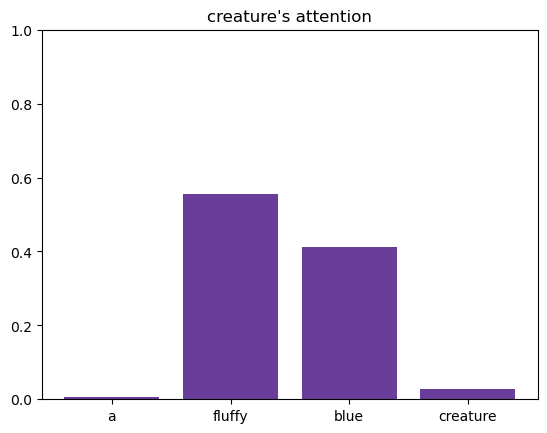

In [4]:
words  = ["a", "fluffy", "blue", "creature"]
keys   = np.array([[-1, .5], [2, .5], [1.8, -.4], [0, 1]])
values = np.array([[0, 0, 0], [1, 0, 0], [0, 1, 0], [0, 0, 1]])   # [fluffiness, blueness, creature-ness]

def attend(q):
    scores  = keys @ q                  # 1-2. query · every key
    weights = softmax(scores)           # 3. softmax
    return scores, weights, weights @ values   # 4. blend the values

q_creature = np.array([1.5, 0])         # "looking for adjectives"
s, w, out = attend(q_creature)
print("scores: ", s); print("weights:", w); print("update ΔE:", out)
bars(words, w, "creature's attention"); plt.show()

Same words, but now the query looks for a noun. The weight should shift to *creature* instead of the adjectives.

weights: [0.247 0.247 0.1   0.407]


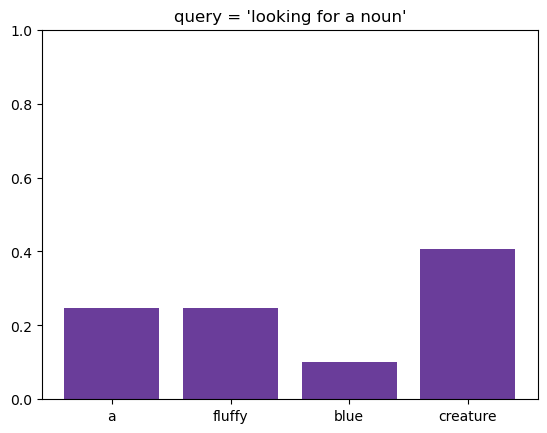

In [5]:
# Change the question: a query that looks for a NOUN instead
s, w, out = attend(np.array([0, 1.0]))
print("weights:", w)
bars(words, w, "query = 'looking for a noun'"); plt.show()

## 4. Every word at once, plus the causal mask

Left: every word's attention at once (rows ask, columns answer). Right: with the causal mask, everything above the diagonal is 0, so no word can look at words that come after it.

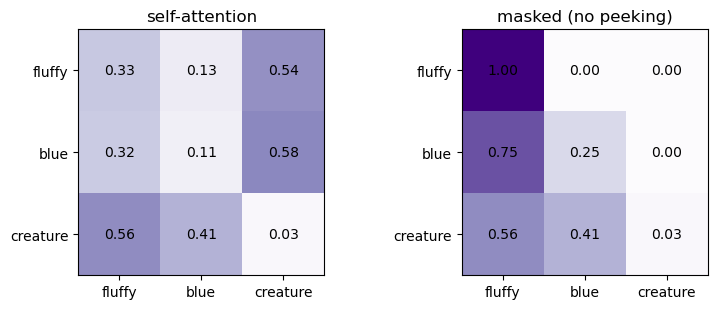

In [ ]:
words3 = ["fluffy", "blue", "creature"]
Q = np.array([[0, 1], [0, 1.2], [1.5, 0]])
K = np.array([[2, .5], [1.8, -.4], [0, 1]])
S = Q @ K.T                                    # all scores: row asks, column answers
mask = np.where(np.triu(np.ones_like(S), k=1) == 1, -np.inf, 0)   # -inf above the diagonal = future words

fig, axs = plt.subplots(1, 2, figsize=(8, 3.2))
for ax, A, title in [(axs[0], softmax(S), "self-attention"), (axs[1], softmax(S + mask), "masked (no peeking)")]:
    ax.imshow(A, cmap="Purples", vmin=0, vmax=1)
    ax.set_xticks(range(3), words3); ax.set_yticks(range(3), words3); ax.set_title(title)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{A[i, j]:.2f}", ha="center", va="center")
plt.tight_layout(); plt.show()

## 5. A real model: GPT-2 on the two "bank" sentences (run this cell before class)
GPT-2 can only look back, so the last word "bank" sees the whole sentence.
GPT-2 also parks a lot of attention on the first word (the "resting spot" from the patterns slide), so that bar is greyed out.

Expect "bank" to attend to **river** in the first sentence and to **in / the / money** in the second. Same word, different context, different meaning.

In [ ]:
import torch
from transformers import GPT2Model, GPT2TokenizerFast

tok = GPT2TokenizerFast.from_pretrained("gpt2")
model = GPT2Model.from_pretrained("gpt2", attn_implementation="eager").eval()

def bank_attention(sentence):
    inputs = tok(sentence, return_tensors="pt")
    with torch.no_grad():
        att = model(**inputs, output_attentions=True).attentions   # 12 layers, each [1, heads, T, T]
    toks = [t.replace("Ġ", "") for t in tok.convert_ids_to_tokens(inputs["input_ids"][0])]
    return toks, [a[0].mean(0)[-1].numpy() for a in att]           # last word's weights, averaged over heads

sentences = ["I sat by the river bank", "I put money in the bank"]
results = [bank_attention(s) for s in sentences]

layer = 5                                  # try different layers
fig, axs = plt.subplots(1, 2, figsize=(10, 3))
for ax, (toks, att) in zip(axs, results):
    w = att[layer]
    ax.bar(toks, w, color=["lightgrey"] + ["#6A3D9A"] * (len(toks) - 1))
    ax.set_ylim(0, 1); ax.set_title(f"'bank' looks at... (layer {layer})")
plt.tight_layout(); plt.show()

for s, (toks, att) in zip(sentences, results):
    print(s)
    for l in range(12):
        w = att[l][1:-1]                   # skip the first word and 'bank' itself
        top = np.argsort(w)[::-1][:2] + 1
        print(f"  layer {l:2}: " + ", ".join(f"{toks[j]} {att[l][j]:.2f}" for j in top))